# MuSiQue 100-question output analysis

This notebook analyzes fixed Top-2 through Top-8 retrieval and Adaptive V3 on the 100-question MuSiQue run. Figures and tables are saved under `analysis/Musique/`.

In [1]:
import csv
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parents[1] if Path.cwd().name == "Musique" else Path.cwd()
OUTPUTS = ROOT / "outputs" / "Musique"
ANALYSIS = ROOT / "analysis" / "Musique"
FIGURES = ANALYSIS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

RUNS = [(f"Top-{k}", f"baseline_top{k}_musique_n100_seed88", "#4C78A8") for k in range(2, 9)]
RUNS.append(("Adaptive V3", "adaptive_v3_musique_n100_seed88", "#E45756"))

def load_summary(folder):
    with (OUTPUTS / folder / "summary.json").open(encoding="utf-8") as handle:
        return json.load(handle)

def load_records(folder):
    with (OUTPUTS / folder / "results.jsonl").open(encoding="utf-8") as handle:
        return [json.loads(line) for line in handle]

def style_axis(ax, title, ylabel):
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


In [2]:
rows = []
for label, folder, _ in RUNS:
    summary = load_summary(folder)
    rows.append({
        "method": label,
        "mean_gold_evidence_pct": summary["gold_evidence_percentage"]["mean"],
        "full_gold_recovery_pct": 100 * summary["full_gold_recovery_rate"],
        "zero_gold_recovery_pct": 100 * summary["zero_gold_recovery_rate"],
        "mean_noise_pct": summary["noise_percentage"]["mean"],
        "mean_paragraphs": summary["raw_paragraphs_retrieved"]["mean"],
        "mean_rounds": summary["retrieval_rounds"]["mean"],
        "mean_reasoning_calls": summary["reasoning_model_calls"]["total"]["mean"],
    })

with (ANALYSIS / "metrics_100.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

rows


[{'method': 'Top-2',
  'mean_gold_evidence_pct': 40.25,
  'full_gold_recovery_pct': 7.000000000000001,
  'zero_gold_recovery_pct': 15.0,
  'mean_noise_pct': 43.0,
  'mean_paragraphs': 2,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-3',
  'mean_gold_evidence_pct': 50.833333333333336,
  'full_gold_recovery_pct': 15.0,
  'zero_gold_recovery_pct': 10.0,
  'mean_noise_pct': 51.66666666666667,
  'mean_paragraphs': 3,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-4',
  'mean_gold_evidence_pct': 57.0,
  'full_gold_recovery_pct': 19.0,
  'zero_gold_recovery_pct': 9.0,
  'mean_noise_pct': 58.75,
  'mean_paragraphs': 4,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-5',
  'mean_gold_evidence_pct': 63.166666666666664,
  'full_gold_recovery_pct': 25.0,
  'zero_gold_recovery_pct': 5.0,
  'mean_noise_pct': 63.4,
  'mean_paragraphs': 5,
  'mean_rounds': 1,
  'mean_reasoning_calls': 0},
 {'method': 'Top-6',
  'mean_gold_evidence_pct': 68.08

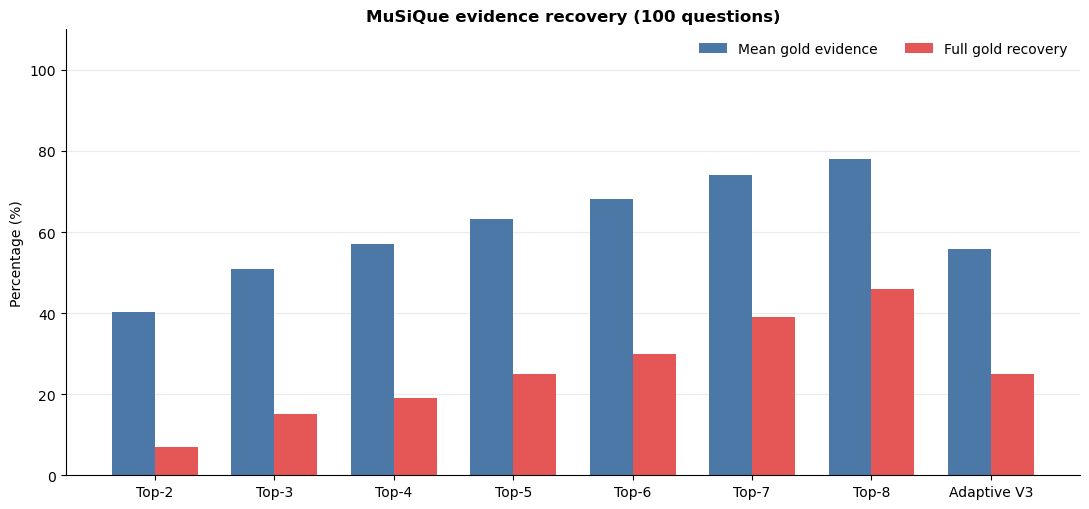

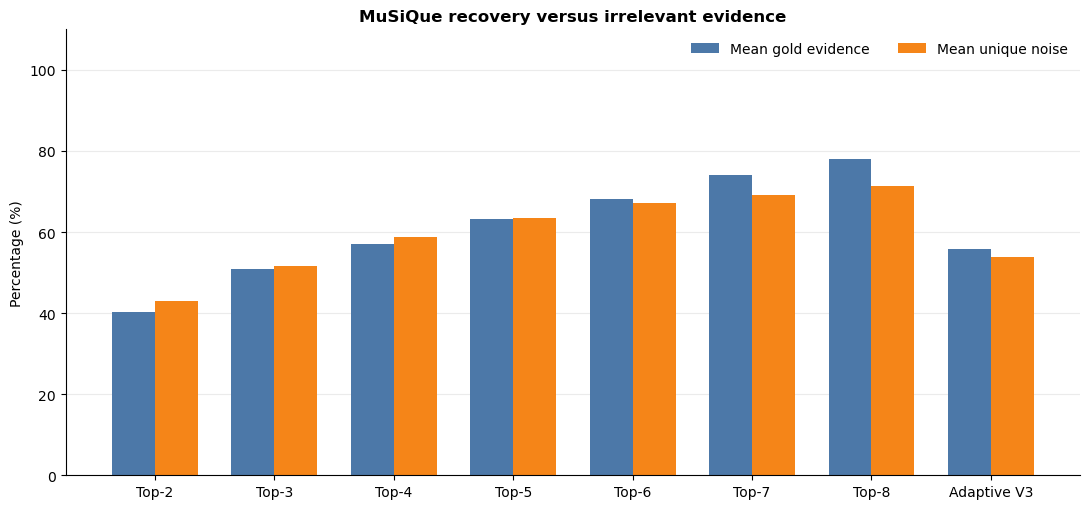

In [3]:
labels = [row["method"] for row in rows]
x = range(len(labels))
width = 0.36
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar([i - width / 2 for i in x], [r["mean_gold_evidence_pct"] for r in rows], width, label="Mean gold evidence", color="#4C78A8")
ax.bar([i + width / 2 for i in x], [r["full_gold_recovery_pct"] for r in rows], width, label="Full gold recovery", color="#E45756")
ax.set_xticks(list(x), labels)
ax.set_ylim(0, 110)
style_axis(ax, "MuSiQue evidence recovery (100 questions)", "Percentage (%)")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "01_evidence_recovery.png", dpi=220)
plt.show()

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bar([i - width / 2 for i in x], [r["mean_gold_evidence_pct"] for r in rows], width, label="Mean gold evidence", color="#4C78A8")
ax.bar([i + width / 2 for i in x], [r["mean_noise_pct"] for r in rows], width, label="Mean unique noise", color="#F58518")
ax.set_xticks(list(x), labels)
ax.set_ylim(0, 110)
style_axis(ax, "MuSiQue recovery versus irrelevant evidence", "Percentage (%)")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "02_recovery_noise_tradeoff.png", dpi=220)
plt.show()


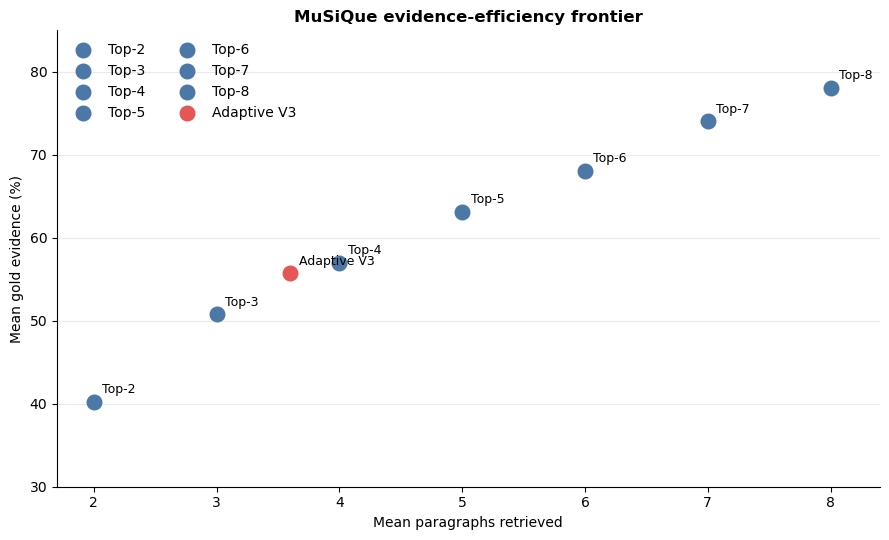

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for row, (_, _, color) in zip(rows, RUNS, strict=True):
    ax.scatter(row["mean_paragraphs"], row["mean_gold_evidence_pct"], s=110, color=color, label=row["method"], zorder=3)
    ax.annotate(row["method"], (row["mean_paragraphs"], row["mean_gold_evidence_pct"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
style_axis(ax, "MuSiQue evidence-efficiency frontier", "Mean gold evidence (%)")
ax.set_xlabel("Mean paragraphs retrieved")
ax.set_xlim(1.7, 8.4)
ax.set_ylim(30, 85)
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "03_efficiency_frontier.png", dpi=220)
plt.show()


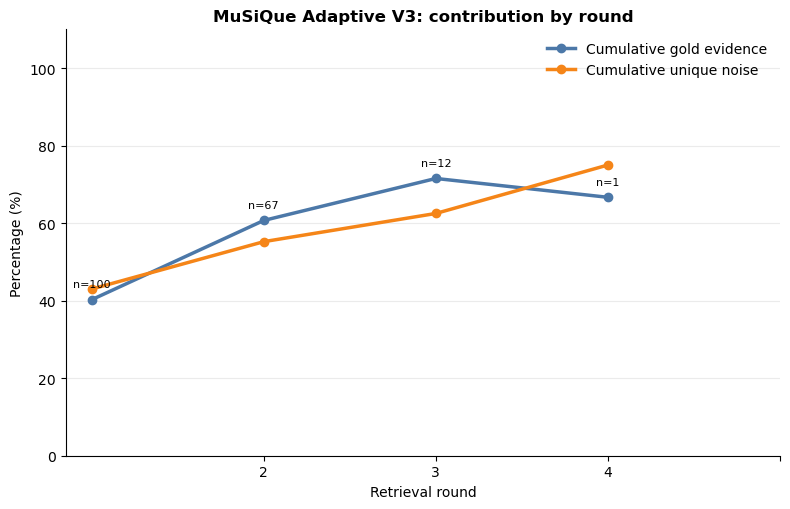

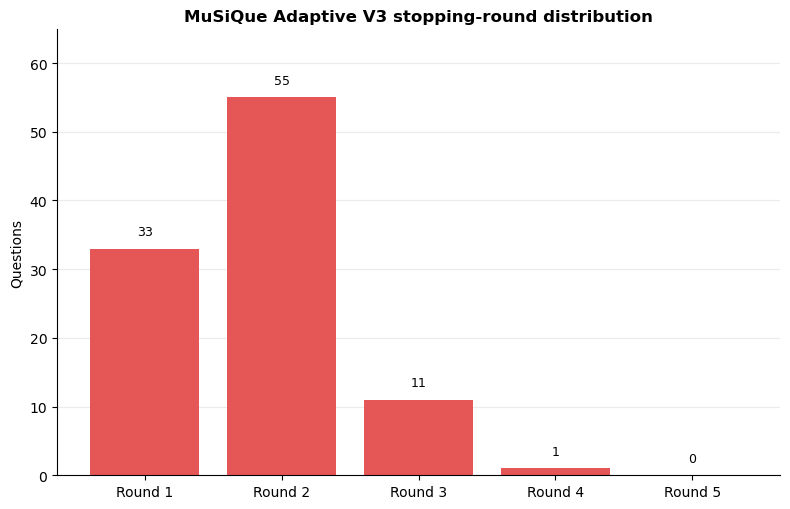

In [5]:
summary = load_summary("adaptive_v3_musique_n100_seed88")
diagnostics = summary["controller_diagnostics"]["gold_recovery_by_round"]
rounds = sorted(diagnostics, key=int)
active = [diagnostics[r]["questions_reaching_round"] for r in rounds]
gold = [diagnostics[r]["mean_cumulative_gold_recall_percentage"] for r in rounds]
noise = [diagnostics[r]["mean_cumulative_unique_noise_percentage"] for r in rounds]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.plot(rounds, gold, marker="o", linewidth=2.5, label="Cumulative gold evidence", color="#4C78A8")
ax.plot(rounds, noise, marker="o", linewidth=2.5, label="Cumulative unique noise", color="#F58518")
for round_number, count, value in zip(rounds, active, gold, strict=True):
    ax.annotate(f"n={count}", (round_number, value), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks([int(r) for r in rounds])
ax.set_ylim(0, 110)
style_axis(ax, "MuSiQue Adaptive V3: contribution by round", "Percentage (%)")
ax.set_xlabel("Retrieval round")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "04_v3_round_progression.png", dpi=220)
plt.show()

counts = summary["stopping_round_counts"]
labels = [f"Round {r}" for r in sorted(counts, key=int)]
values = [counts[r] for r in sorted(counts, key=int)]
fig, ax = plt.subplots(figsize=(8, 5.2))
bars = ax.bar(labels, values, color="#E45756")
for bar, value in zip(bars, values, strict=True):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 2, str(value), ha="center", fontsize=9)
style_axis(ax, "MuSiQue Adaptive V3 stopping-round distribution", "Questions")
ax.set_ylim(0, max(values) * 1.18)
fig.tight_layout()
fig.savefig(FIGURES / "05_v3_stopping_rounds.png", dpi=220)
plt.show()


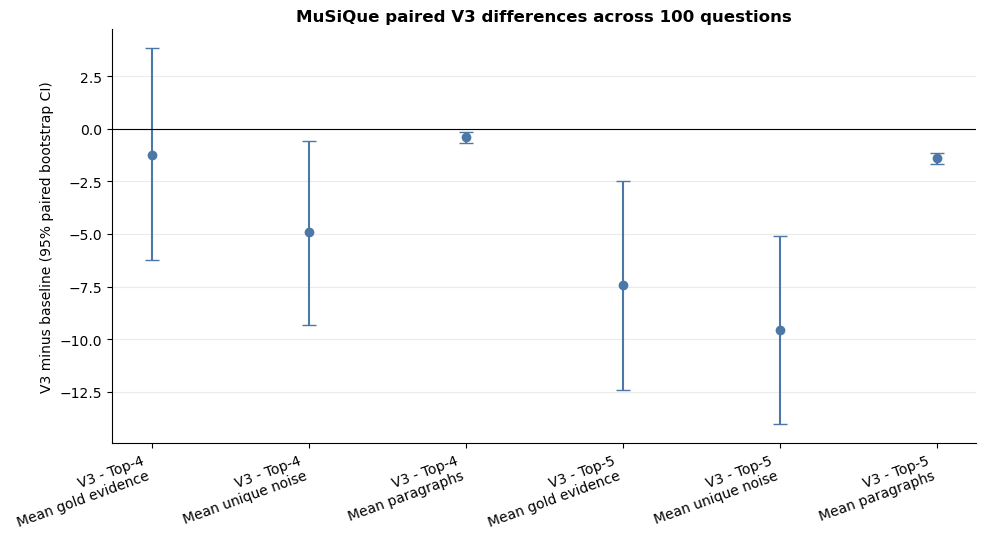

MuSiQue analysis validation passed


In [6]:
def paired_values(folder, metric):
    baseline = load_records(folder)
    v3 = load_records("adaptive_v3_musique_n100_seed88")
    if [r["question_id"] for r in baseline] != [r["question_id"] for r in v3]:
        raise ValueError(f"question ordering differs for {folder}")
    return np.array([r[metric] for r in baseline], dtype=float), np.array([r[metric] for r in v3], dtype=float)

def bootstrap_ci(differences, seed=88):
    rng = np.random.default_rng(seed)
    samples = differences[rng.integers(0, len(differences), size=(10000, len(differences)))]
    means = samples.mean(axis=1)
    return float(differences.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

ci_rows = []
for label, folder in [("Top-4", "baseline_top4_musique_n100_seed88"), ("Top-5", "baseline_top5_musique_n100_seed88")]:
    for metric, display in [("gold_evidence_percentage", "Mean gold evidence"), ("noise_percentage", "Mean unique noise"), ("raw_paragraphs_retrieved", "Mean paragraphs")]:
        baseline, v3 = paired_values(folder, metric)
        mean_delta, lower, upper = bootstrap_ci(v3 - baseline)
        ci_rows.append({"comparison": f"V3 - {label}", "metric": display, "mean_delta": mean_delta, "ci_lower": lower, "ci_upper": upper})

with (ANALYSIS / "paired_bootstrap_ci.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(ci_rows[0]))
    writer.writeheader()
    writer.writerows(ci_rows)

labels = [f"{r['comparison']}\n{r['metric']}" for r in ci_rows]
means = [r["mean_delta"] for r in ci_rows]
errors = [[r["mean_delta"] - r["ci_lower"] for r in ci_rows], [r["ci_upper"] - r["mean_delta"] for r in ci_rows]]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(range(len(ci_rows)), means, yerr=errors, fmt="o", capsize=5, color="#4C78A8")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(len(ci_rows)), labels, rotation=20, ha="right")
ax.set_ylabel("V3 minus baseline (95% paired bootstrap CI)")
ax.set_title("MuSiQue paired V3 differences across 100 questions", weight="bold")
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "06_paired_bootstrap_ci.png", dpi=220)
plt.show()

stop_rows = []
v3_rows = load_records("adaptive_v3_musique_n100_seed88")
for reason, count in sorted(Counter(r["stop_reason"] for r in v3_rows).items()):
    subset = [r for r in v3_rows if r["stop_reason"] == reason]
    complete = sum(r["gold_evidence_percentage"] == 100 for r in subset)
    stop_rows.append({"stop_reason": reason, "questions": count, "gold_complete": complete, "gold_complete_pct": 100 * complete / count})
with (ANALYSIS / "stopping_quality.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(stop_rows[0]))
    writer.writeheader()
    writer.writerows(stop_rows)

assert len(rows) == 8
assert round(rows[-1]["mean_gold_evidence_pct"], 2) == 55.75
assert round(rows[-1]["full_gold_recovery_pct"], 2) == 25.0
assert all((FIGURES / f"0{i}_" + "x").exists() is False for i in [])
print("MuSiQue analysis validation passed")
